**PROJECT 3: FINANCIAL DATA ANALYSIS & FORECASTING**

In [52]:



import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import dash
from dash import dcc, html
from dash.dependencies import Input, Output
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.linear_model import LinearRegression



# -------------------------------
# 1️⃣ Load Dataset
# -------------------------------
df = pd.read_csv("/content/Finance_data.csv")

# Display first rows
print(df.head())


   gender  age Investment_Avenues  Mutual_Funds  Equity_Market  Debentures  \
0  Female   34                Yes             1              2           5   
1  Female   23                Yes             4              3           2   
2    Male   30                Yes             3              6           4   
3    Male   22                Yes             2              1           3   
4  Female   24                 No             2              1           3   

   Government_Bonds  Fixed_Deposits  PPF  Gold  ...           Duration  \
0                 3               7    6     4  ...          1-3 years   
1                 1               5    6     7  ...  More than 5 years   
2                 2               5    1     7  ...          3-5 years   
3                 7               6    4     5  ...   Less than 1 year   
4                 6               4    5     7  ...   Less than 1 year   

  Invest_Monitor   Expect       Avenue What are your savings objectives?  \
0        M

Data Cleaning

In [43]:

# Drop duplicates
df.drop_duplicates(inplace=True)

# Fill missing numeric values with 0
investment_cols = ['Mutual_Funds','Equity_Market','Debentures','Government_Bonds',
                   'Fixed_Deposits','PPF','Gold']
df[investment_cols] = df[investment_cols].fillna(0)

# Fill missing age with median
df['age'] = df['age'].fillna(df['age'].median())

# Optional: Convert duration to numeric if exists
if 'Duration' in df.columns:
    df['Duration'] = pd.to_numeric(df['Duration'], errors='coerce').fillna(0)





Trend Analysis (EDA)


Total Investments by Avenue:
 Mutual_Funds        102
Equity_Market       139
Debentures          230
Government_Bonds    186
Fixed_Deposits      143
PPF                  81
Gold                239
dtype: int64


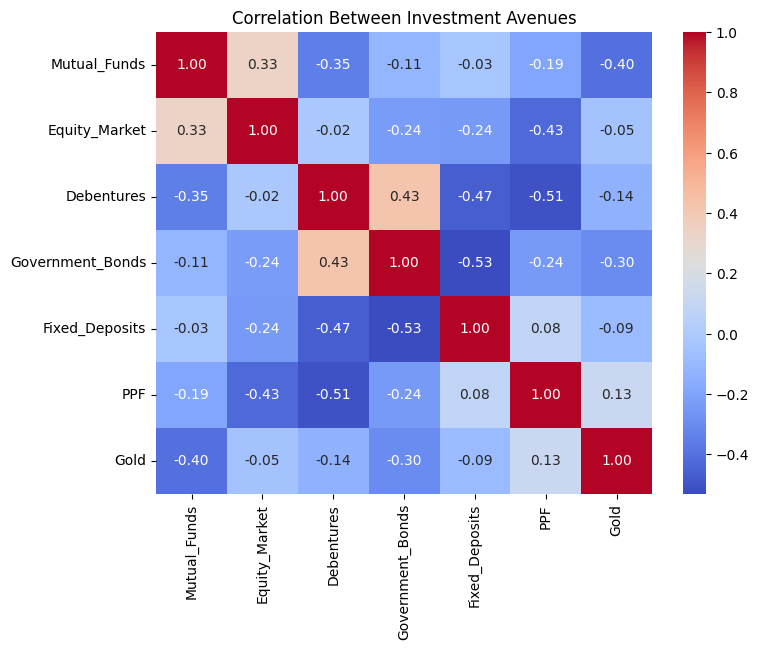

In [42]:

# Total investments per avenue
total_investments = df[investment_cols].sum()
print("\nTotal Investments by Avenue:\n", total_investments)

# Correlation heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df[investment_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Between Investment Avenues')
plt.show()

Data Visualization

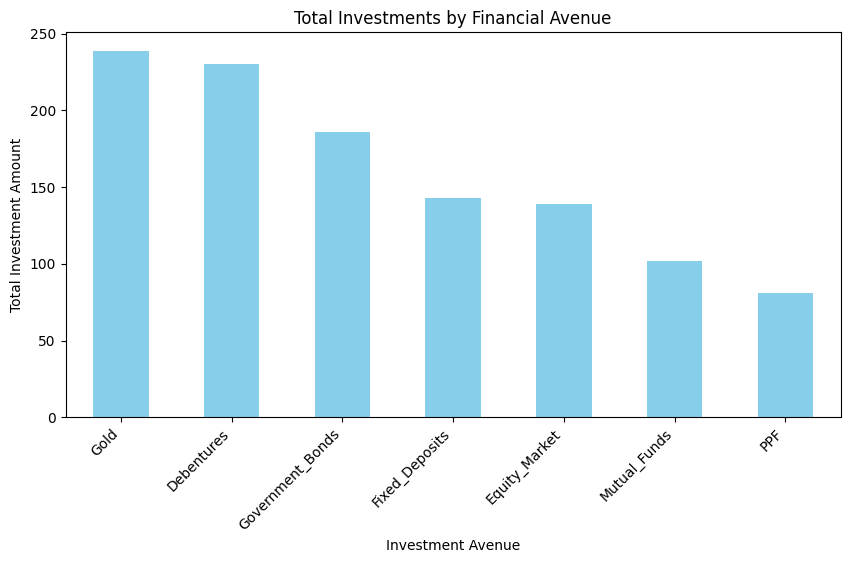

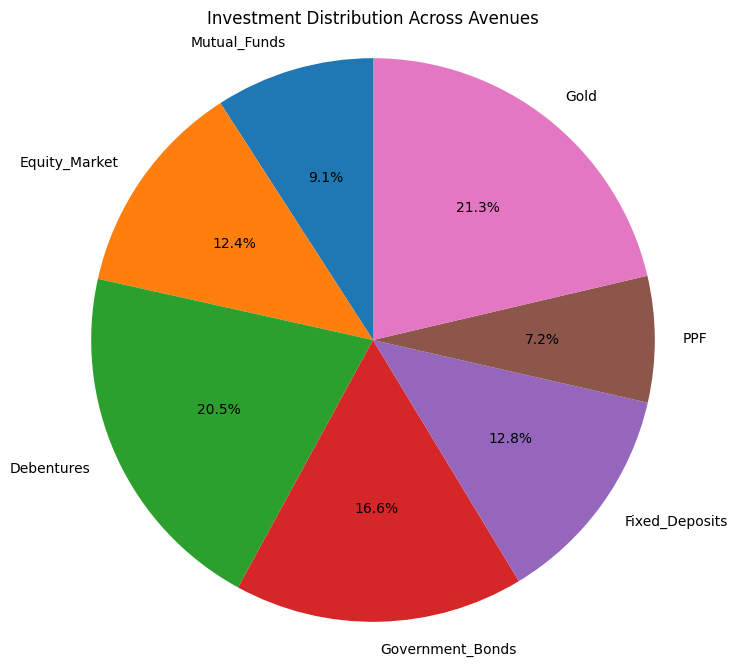

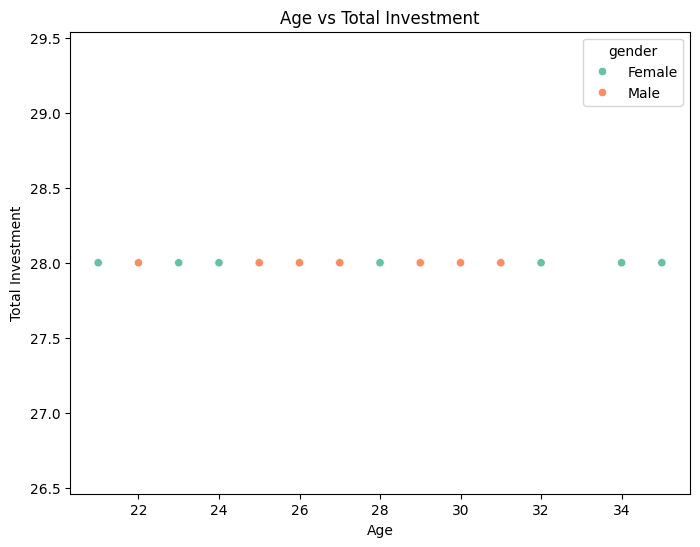

In [44]:

# Bar chart - Total Investments by Avenue
plt.figure(figsize=(10,5))
total_investments.sort_values(ascending=False).plot(kind='bar', color='skyblue')
plt.title('Total Investments by Financial Avenue')
plt.xlabel('Investment Avenue')
plt.ylabel('Total Investment Amount')
plt.xticks(rotation=45, ha='right')
plt.show()

# Pie chart - Proportion of Investments
plt.figure(figsize=(8,8))
plt.pie(total_investments, labels=total_investments.index, autopct='%1.1f%%', startangle=90)
plt.title('Investment Distribution Across Avenues')
plt.axis('equal')
plt.show()

# Scatter plot - Age vs Total Investment
df['Total_Investment'] = df[investment_cols].sum(axis=1)
plt.figure(figsize=(8,6))
sns.scatterplot(x='age', y='Total_Investment', hue='gender', data=df, palette='Set2')
plt.title('Age vs Total Investment')
plt.xlabel('Age')
plt.ylabel('Total Investment')
plt.show()


Forecasting

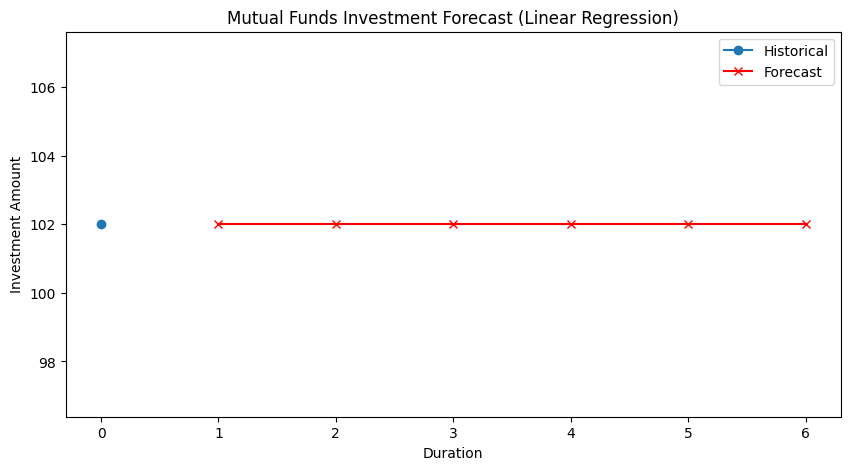

In [51]:


if 'Duration' in df.columns:
    ts = df.groupby('Duration')['Mutual_Funds'].sum().reset_index()

    if len(ts) >= 1:
        # Ensure Duration is integer
        ts['Duration'] = ts['Duration'].astype(int)
        X = ts[['Duration']].values
        y = ts['Mutual_Funds'].values

        # Fit linear regression
        model = LinearRegression().fit(X, y)

        # Predict next 6 durations
        start = int(X[-1][0])
        future_X = np.array(range(start+1, start+7)).reshape(-1,1)
        forecast = model.predict(future_X)

        # Plot historical + forecast
        plt.figure(figsize=(10,5))
        plt.plot(X, y, label='Historical', marker='o')
        plt.plot(future_X, forecast, label='Forecast', marker='x', color='red')
        plt.title('Mutual Funds Investment Forecast (Linear Regression)')
        plt.xlabel('Duration')
        plt.ylabel('Investment Amount')
        plt.legend()
        plt.show()
    else:
        print("No data available for forecasting.")


Interactive Dashboard using Dash

In [53]:

app = dash.Dash(__name__)
app.title = "Financial Data Dashboard"

app.layout = html.Div([
    html.H1("Financial Investments Dashboard", style={'textAlign':'center'}),

    html.Div([
        html.Label("Select Investment Avenue:"),
        dcc.Dropdown(
            id='avenue-filter',
            options=[{'label': col, 'value': col} for col in investment_cols],
            value=investment_cols[0]
        ),
    ], style={'width':'40%', 'display':'inline-block'}),

    html.Div([
        html.Label("Select Gender:"),
        dcc.Dropdown(
            id='gender-filter',
            options=[{'label': g, 'value': g} for g in df['gender'].unique()],
            multi=True,
            value=df['gender'].unique().tolist()
        )
    ], style={'width':'40%', 'display':'inline-block', 'margin-left':'20px'}),

    html.Br(), html.Br(),
    dcc.Graph(id='investment-bar'),
    dcc.Graph(id='investment-age-scatter')
])

@app.callback(
    [Output('investment-bar', 'figure'),
     Output('investment-age-scatter', 'figure')],
    [Input('avenue-filter', 'value'),
     Input('gender-filter', 'value')]
)
def update_dashboard(selected_avenue, selected_gender):
    filtered_df = df[df['gender'].isin(selected_gender)]

    # Bar chart - selected investment avenue
    bar_data = filtered_df.groupby('gender')[selected_avenue].sum().reset_index()
    fig_bar = px.bar(bar_data, x='gender', y=selected_avenue, color='gender',
                     title=f'Total {selected_avenue} by Gender')

    # Scatter plot - age vs selected investment
    fig_scatter = px.scatter(filtered_df, x='age', y=selected_avenue, color='gender',
                             title=f'{selected_avenue} Investment vs Age',
                             hover_data=['Total_Investment'])

    return fig_bar, fig_scatter

# Run the dashboard
if __name__ == '__main__':
    app.run(debug=True)

<IPython.core.display.Javascript object>

Insights Generation

In [55]:



numeric_cols = ['Mutual_Funds', 'Equity_Market', 'Debentures', 'Government_Bonds', 'Fixed_Deposits', 'PPF', 'Gold']

# 1️⃣ Overall Financial Health
print("----- Overall Financial Health -----")
total_investment = df[numeric_cols].sum().sum()
avg_investment_per_customer = df[numeric_cols].sum(axis=1).mean()
print(f"Total Investment Across All Customers: ${total_investment:,.2f}")
print(f"Average Investment per Customer: ${avg_investment_per_customer:,.2f}")

# 2️⃣ Top Investment Avenues
print("\n----- Top Investment Avenues -----")
total_by_avenue = df[numeric_cols].sum().sort_values(ascending=False)
print(total_by_avenue)

# 3️⃣ Potential Future Performance
# Using forecasted Mutual Funds (from previous forecast)
if 'future_X' in locals() and 'forecast' in locals():
    forecasted_total = forecast.sum()
    print(f"\nForecasted Mutual Funds Investment for next 6 periods: ${forecasted_total:,.2f}")
    if forecasted_total > df['Mutual_Funds'].sum():
        print("Positive trend expected in Mutual Funds investments.")
    else:
        print("Mutual Funds investments might decline, consider promotions or incentives.")

# 4️⃣ Areas for Investment or Cost Reduction
# Identify low-performing avenues
low_investment = total_by_avenue[total_by_avenue < total_by_avenue.mean()]
print("\n----- Low-performing Investment Avenues (consider cost reduction or promotion) -----")
print(low_investment)

# 5️⃣ Customer Insights
# 5️⃣ Customer Insights
print("\n----- Customer Insights -----")

# Compute total investment per row
df['Total_Investment'] = df[numeric_cols].sum(axis=1)

# High-value customers: top 25%
high_value_customers = df[df['Total_Investment'] > df['Total_Investment'].quantile(0.75)]
print(f"Number of high-value customers: {len(high_value_customers)}")

print("Top 5 high-value customers by total investment:")
print(high_value_customers[['gender', 'age', 'Total_Investment']].sort_values(by='Total_Investment', ascending=False).head(5))



----- Overall Financial Health -----
Total Investment Across All Customers: $1,120.00
Average Investment per Customer: $28.00

----- Top Investment Avenues -----
Gold                239
Debentures          230
Government_Bonds    186
Fixed_Deposits      143
Equity_Market       139
Mutual_Funds        102
PPF                  81
dtype: int64

Forecasted Mutual Funds Investment for next 6 periods: $612.00
Positive trend expected in Mutual Funds investments.

----- Low-performing Investment Avenues (consider cost reduction or promotion) -----
Fixed_Deposits    143
Equity_Market     139
Mutual_Funds      102
PPF                81
dtype: int64

----- Customer Insights -----
Number of high-value customers: 0
Top 5 high-value customers by total investment:
Empty DataFrame
Columns: [gender, age, Total_Investment]
Index: []
